# This file is to test the processed data before it is used for training

## tests include the flare flags (binary), retrieved flare times (integer), number of flares (integer), and separation of light curves into flare/non-flare data

In [ ]:
#imports modules
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#set root and import functions
import sys
sys.path.insert(0, str(Path.cwd().parent))
from src.utilities import build_individual_grb_table, separate_flare_data

In [ ]:
#read in data
df=pd.read_csv('../data/xrt_data_from_phd.csv')

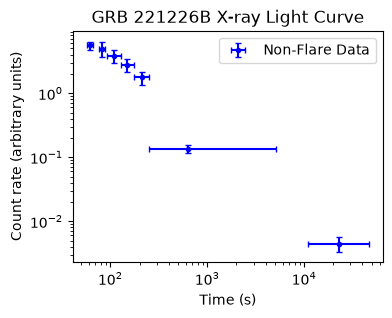

In [ ]:
#load and test a light curve for a single random GRB
choice=np.random.choice(df['GRB'].unique())
data=build_individual_grb_table(df,choice)
# print(data.columns)

#separate the flare data, if any
flare_data,non_flare_data,full_data=separate_flare_data(data)

#make plot 
fig,axs=plt.subplots(figsize=(4,3))

#plot flare data
if flare_data is not None:
    axs.errorbar(flare_data["Time"], flare_data["Rate"], xerr=[np.abs(flare_data["TimeNeg"]),np.abs(flare_data["TimePos"])], yerr=[np.abs(flare_data["RateNeg"]),np.abs(flare_data["RatePos"])] ,fmt="o", markersize=3,capsize=2, color='red', label='Flare Data')

#plot non flare data
if non_flare_data is not None:
    axs.errorbar(non_flare_data["Time"], non_flare_data["Rate"], xerr=[np.abs(non_flare_data["TimeNeg"]),np.abs(non_flare_data["TimePos"])], yerr=[np.abs(non_flare_data["RateNeg"]),np.abs(non_flare_data["RatePos"])] ,fmt="o", markersize=3,capsize=2, color='blue', label='Non-Flare Data')

# #plot full LC
# axs.errorbar(full_data["Time"], full_data["Rate"], xerr=[np.abs(full_data["TimeNeg"]),np.abs(full_data["TimePos"])], yerr=[np.abs(full_data["RateNeg"]),np.abs(full_data["RatePos"])] ,fmt="o", markersize=3,capsize=2,color='blue', label='Non-flare Data')

#format and produce plot
axs.set_xscale("log")
axs.set_yscale("log")
axs.set_xlabel("Time (s)")
axs.set_ylabel("Count rate (arbitrary units)")
axs.set_title("GRB {} X-ray Light Curve".format(data["GRB"].iloc[0]))
axs.legend()
plt.show()


In [ ]:
# Compare the different versions (works whether a dataframe is None or empty)
print("Flare data:")
print(flare_data.head(200) if flare_data is not None else "None (no flares)")

print("\nNon-flare data:")
print(non_flare_data.head(200))

print("\nFull data:")
print(full_data.head(200))

# Sanity check: flare + non-flare rows should equal the full data
n_flare=0 if flare_data is None else len(flare_data)
print(f"\nflare ({n_flare}) + non-flare ({len(non_flare_data)}) = {n_flare + len(non_flare_data)}, full={len(full_data)}")

Flare data:
None (no flares)

Non-flare data:
          GRB          Time       TimePos       TimeNeg      Rate   RatePos  \
8739  221226B     61.064876      5.114343     -4.180803  5.593811  0.821443   
8740  221226B     81.593000      5.757000     -5.555000  4.884023  1.356158   
8741  221226B    108.069000     19.674000    -15.429000  3.796902  0.853580   
8742  221226B    149.019000     26.362000    -21.277000  2.797939  0.628159   
8743  221226B    211.360000     39.242000    -35.978000  1.763520  0.398062   
8744  221226B    633.141000   4494.993000   -382.540000  0.135689  0.021048   
8745  221226B  22688.324000  23518.752000 -11612.607000  0.004495  0.001127   

       RateNeg    lctype  Flare_1_start  Flare_1_end  ...  Flare_10_start  \
8739 -0.824158  Nobreaks            NaN          NaN  ...             NaN   
8740 -1.195765  Nobreaks            NaN          NaN  ...             NaN   
8741 -0.853580  Nobreaks            NaN          NaN  ...             NaN   
8742 -0.62815